# Notebook 2 — Temporal Split & Baseline Models
**What this notebook does:**
- Creates time-based train/test split (2018 boundary)
- TF-IDF vectorization
- Trains Logistic Regression baseline
- Trains Random Forest baseline
- Generates confusion matrix graphs
- Saves models for comparison with DistilBERT

## Step 1 — Imports & Load Clean Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)
import warnings
warnings.filterwarnings('ignore')

# Load clean data from Notebook 1
df = pd.read_csv('clean_data.csv')
print(f'Data loaded: {len(df):,} records')
print(f'Year range: {df["year"].min()} — {df["year"].max()}')

Data loaded: 193,364 records
Year range: 1999 — 2023


## Step 2 — Temporal Split (Core of Drift Simulation)

In [3]:
# TIME-BASED SPLIT — NOT RANDOM
# This simulates real deployment:
# Model trained on OLD data, tested on NEW/DRIFTED data

df_train = df[df['year'] <= 2018].copy()
df_test  = df[df['year'] >  2018].copy()

print('=' * 50)
print('TEMPORAL SPLIT RESULTS')
print('=' * 50)
print(f'Training Set  (1999-2018): {len(df_train):,} reviews')
print(f'Test/Drift Set (2019-2023): {len(df_test):,} reviews')
print(f'\nTraining Sentiment Distribution:')
print(df_train['sentiment'].value_counts())
print(f'\nTest Sentiment Distribution:')
print(df_test['sentiment'].value_counts())

TEMPORAL SPLIT RESULTS
Training Set  (1999-2018): 86,853 reviews
Test/Drift Set (2019-2023): 106,511 reviews

Training Sentiment Distribution:
sentiment
positive    69252
negative    10903
neutral      6698
Name: count, dtype: int64

Test Sentiment Distribution:
sentiment
positive    84757
negative    14590
neutral      7164
Name: count, dtype: int64


## Step 3 — TF-IDF Vectorization

In [4]:
# IMPORTANT: TF-IDF fit ONLY on training data
# This prevents data leakage from test/future data

print('Fitting TF-IDF on training data...')
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2),  # Unigrams + Bigrams
    min_df=5             # Word must appear in at least 5 reviews
)

X_train = tfidf.fit_transform(df_train['text'].fillna(''))
X_test  = tfidf.transform(df_test['text'].fillna(''))
y_train = df_train['label']
y_test  = df_test['label']

print(f'TF-IDF fit complete ✓')
print(f'Training matrix shape: {X_train.shape}')
print(f'Test matrix shape:     {X_test.shape}')
print(f'Features (words): {X_train.shape[1]:,}')

# Save TF-IDF for later use in drift detection
with open('../models/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)
print('TF-IDF vectorizer saved ✓')

Fitting TF-IDF on training data...
TF-IDF fit complete ✓
Training matrix shape: (86853, 5000)
Test matrix shape:     (106511, 5000)
Features (words): 5,000
TF-IDF vectorizer saved ✓


## Step 4 — Logistic Regression (Baseline 1)

In [5]:
print('Training Logistic Regression...')
lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',  # Handle class imbalance
    random_state=42,
    C=1.0
)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_f1  = f1_score(y_test, y_pred_lr, average='weighted')

print('\n' + '='*50)
print('LOGISTIC REGRESSION RESULTS')
print('='*50)
print(classification_report(
    y_test, y_pred_lr,
    target_names=['Negative','Neutral','Positive']
))
print(f'Overall Accuracy:    {lr_acc:.4f} ({lr_acc*100:.2f}%)')
print(f'Weighted F1-Score:   {lr_f1:.4f}')

# Save model
with open('../models/logistic_regression.pkl', 'wb') as f:
    pickle.dump(lr, f)
print('\nModel saved to models/logistic_regression.pkl ✓')

Training Logistic Regression...

LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

    Negative       0.56      0.71      0.63     14590
     Neutral       0.18      0.48      0.26      7164
    Positive       0.96      0.78      0.86     84757

    accuracy                           0.75    106511
   macro avg       0.57      0.66      0.58    106511
weighted avg       0.86      0.75      0.79    106511

Overall Accuracy:    0.7497 (74.97%)
Weighted F1-Score:   0.7889

Model saved to models/logistic_regression.pkl ✓


## Step 5 — Random Forest (Baseline 2)

In [6]:
print('Training Random Forest (this takes 3-5 minutes)...')
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1           # Use all CPU cores
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_acc = accuracy_score(y_test, y_pred_rf)
rf_f1  = f1_score(y_test, y_pred_rf, average='weighted')

print('\n' + '='*50)
print('RANDOM FOREST RESULTS')
print('='*50)
print(classification_report(
    y_test, y_pred_rf,
    target_names=['Negative','Neutral','Positive']
))
print(f'Overall Accuracy:    {rf_acc:.4f} ({rf_acc*100:.2f}%)')
print(f'Weighted F1-Score:   {rf_f1:.4f}')

# Save model
with open('../models/random_forest.pkl', 'wb') as f:
    pickle.dump(rf, f)
print('\nModel saved to models/random_forest.pkl ✓')

Training Random Forest (this takes 3-5 minutes)...

RANDOM FOREST RESULTS
              precision    recall  f1-score   support

    Negative       0.59      0.69      0.64     14590
     Neutral       0.21      0.11      0.14      7164
    Positive       0.91      0.92      0.91     84757

    accuracy                           0.83    106511
   macro avg       0.57      0.57      0.57    106511
weighted avg       0.82      0.83      0.82    106511

Overall Accuracy:    0.8342 (83.42%)
Weighted F1-Score:   0.8245

Model saved to models/random_forest.pkl ✓


## Step 6 — Confusion Matrix Graphs

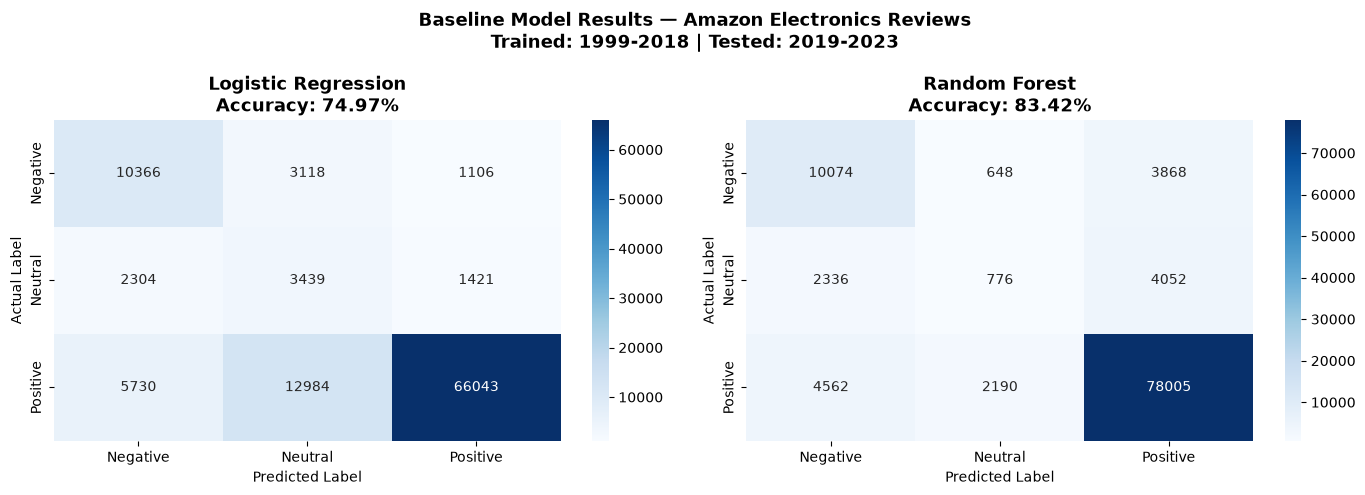

Confusion matrix saved ✓


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title, acc in zip(
    axes,
    [y_pred_lr, y_pred_rf],
    ['Logistic Regression', 'Random Forest'],
    [lr_acc, rf_acc]
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Negative','Neutral','Positive'],
        yticklabels=['Negative','Neutral','Positive']
    )
    ax.set_title(f'{title}\nAccuracy: {acc:.2%}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Actual Label')
    ax.set_xlabel('Predicted Label')

plt.suptitle(
    'Baseline Model Results — Amazon Electronics Reviews\n'
    'Trained: 1999-2018 | Tested: 2019-2023',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('../outputs/02_baseline_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Confusion matrix saved ✓')

## Step 7 — Baseline Comparison Summary

In [8]:
# Summary table
summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'DistilBERT (Next)'],
    'Accuracy': [f'{lr_acc:.2%}', f'{rf_acc:.2%}', 'TBD'],
    'Weighted F1': [f'{lr_f1:.4f}', f'{rf_f1:.4f}', 'TBD'],
    'Drift Detection': ['❌ No', '❌ No', '✅ Yes'],
    'SHAP Explanation': ['❌ No', '❌ No', '✅ Yes'],
    'Role': ['Baseline 1', 'Baseline 2', 'Main Model']
})

print('='*70)
print('MODEL COMPARISON SUMMARY')
print('='*70)
print(summary.to_string(index=False))

# Save results
summary.to_csv('../outputs/baseline_results.csv', index=False)
print('\nResults saved to outputs/baseline_results.csv ✓')
print('\n✅ Notebook 2 Complete! Run Notebook 3 next.')

MODEL COMPARISON SUMMARY
              Model Accuracy Weighted F1 Drift Detection SHAP Explanation       Role
Logistic Regression   74.97%      0.7889            ❌ No             ❌ No Baseline 1
      Random Forest   83.42%      0.8245            ❌ No             ❌ No Baseline 2
  DistilBERT (Next)      TBD         TBD           ✅ Yes            ✅ Yes Main Model

Results saved to outputs/baseline_results.csv ✓

✅ Notebook 2 Complete! Run Notebook 3 next.


## Save Split Data for Next Notebooks

In [11]:
df_train.to_csv('train_data.csv', index=False)
df_test.to_csv('test_data.csv', index=False)
print(f'Training data saved: {len(df_train):,} records ✓')
print(f'Test data saved: {len(df_test):,} records ✓')

Training data saved: 86,853 records ✓
Test data saved: 106,511 records ✓
